# Segmentação da árvore vascular da retina — Projeto Final

**Processamento Digital de Imagens**

Este notebook desenvolveu, etapa por etapa, o projeto de segmentação de vasos da retina descrito no relatório técnico. Ele carregou imagens coloridas do conjunto CHASE, extrai o canal verde, realça vasos com CLAHE e top-hat, segmenta por histerese, limpa a máscara com morfologia, esqueletiza a árvore vascular, calcula métricas e executa comparações e análises de falhas.


### O que foi realizado

- comparações de realce e limiarização com Dice, IoU, sensibilidade e especificidade;
- estudo univariado da sensibilidade dos parâmetros e estudo de ruído/PSNR;
- métricas reservadas de segmentação, comprimento e ramificações;
- figura das etapas do pipeline e mapas de erro;
- arquivos CSV e previsões opcionais 1.png–20.png.



## 1. Preparação do ambiente

Instalamos bibliotecas para leitura de imagens, filtros, morfologia, esqueletização, estatística e gráficos. O código roda em CPU; GPU não é necessária para este método clássico.

In [1]:
!pip -q install opencv-python-headless scikit-image scipy pandas matplotlib pillow


In [2]:
import os, zipfile, urllib.request, json, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import convolve
from scipy.stats import wilcoxon
from skimage.morphology import skeletonize
from skimage.filters import threshold_otsu, threshold_local, apply_hysteresis_threshold, frangi
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
print('OpenCV', cv2.__version__, '| NumPy', np.__version__)


OpenCV 5.0.0 | NumPy 2.2.6


## 2. Obtenção e inspeção do CHASE

Extraia o dataset para a pasta `CHASE/` no Google Drive ou em `./CHASE/` mantendo a estrutura esperada.

In [3]:
import sys
IN_COLAB = 'google.colab' in sys.modules
DATA_ROOT = Path('/content/CHASE') if IN_COLAB else Path('./CHASE')
assert (DATA_ROOT/'images'/'Image_10R.jpg').exists(), 'Não encontrei a estrutura CHASE esperada.'
print('Imagens anotadas:', len(list((DATA_ROOT/'images').glob('*.jpg'))))


Imagens anotadas: 28


Imagem: (960, 999, 3) uint8 | FOV: 671039 | pixels rotulados como vaso: 51119


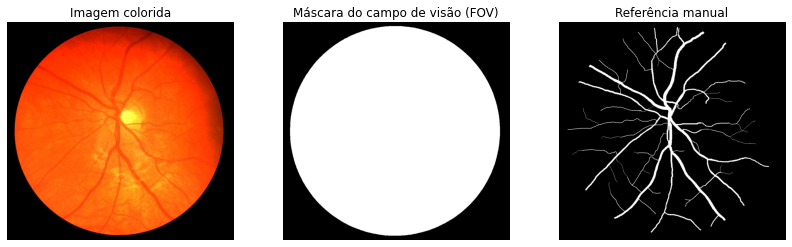

In [4]:
def load_image(name):
    """Lê imagem RGB, máscara FOV e anotação manual."""
    rgb=np.array(Image.open(DATA_ROOT/'images'/f'{name}.jpg').convert('RGB'))
    fov=np.array(Image.open(DATA_ROOT/'masks'/f'{name}.png'))>0
    gt=np.array(Image.open(DATA_ROOT/'manual'/f'{name}_1stHO.png'))>0
    return rgb, fov, gt

rgb, fov, gt = load_image("Image_11L")
print('Imagem:', rgb.shape, rgb.dtype, '| FOV:', fov.sum(), '| pixels rotulados como vaso:', gt.sum())
fig, ax = plt.subplots(1,3,figsize=(14,4))
ax[0].imshow(rgb); ax[0].set_title('Imagem colorida')
ax[1].imshow(fov,cmap='gray'); ax[1].set_title('Máscara do campo de visão (FOV)')
ax[2].imshow(gt,cmap='gray'); ax[2].set_title('Referência manual')
for a in ax: a.axis('off')
plt.show()


## 3. Etapa 1 — realce dos vasos

### 3.1 Canal verde e preenchimento do exterior

Vasos aparecem escuros no canal verde por causa da absorção da hemoglobina. Antes de filtrar, substituímos o fundo externo ao FOV pela média dos pixels internos. Isso reduz respostas falsas na borda circular do campo.

### 3.2 Suavização Gaussiana

Um desvio-padrão pequeno reduz ruído de alta frequência. A suavização excessiva apaga vasos finos; por isso `smooth` também será testado.

### 3.3 CLAHE

A equalização adaptativa com limite de contraste (CLAHE) compensa variações locais de iluminação. `clip` controla amplificação e `tile` define o tamanho da grade de blocos.

### 3.4 Top-hat morfológico

Invertendo o canal verde, os vasos ficam claros. O top-hat branco subtrai a abertura morfológica da imagem e destaca estruturas claras menores do que o elemento estruturante. `se` é o diâmetro do elemento elíptico em pixels. Um elemento pequeno pode deixar vasos largos incompletos; um grande demais pode deixar passar variações de fundo.

O Frangi está incluído como alternativa multiescala; não substitui o método principal exigido.


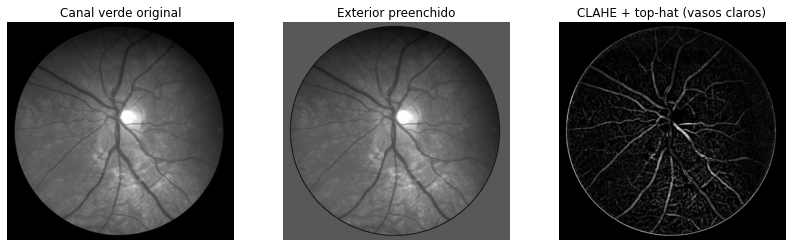

In [5]:
def fill_outside(gray, fov):
    out=gray.copy()
    out[~fov]=int(gray[fov].mean())
    return out

def enhance(rgb, fov, enhancer='clahe_tophat', clip=2.0, tile=8, se=15, smooth=1.0):
    g=fill_outside(rgb[...,1],fov)
    if enhancer=='frangi':
        response=frangi(g.astype(float)/255.0,sigmas=(1,2,3),black_ridges=True)
        response[~fov]=0
        return (255*response/(response.max()+1e-9)).astype(np.uint8)
    if smooth>0:
        g=cv2.GaussianBlur(g,(0,0),smooth)
    if enhancer in ('clahe_tophat','clahe'):
        g=cv2.createCLAHE(clipLimit=clip,tileGridSize=(tile,tile)).apply(g)
    inv=255-g
    if enhancer in ('clahe_tophat','tophat'):
        kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(se,se))
        inv=cv2.morphologyEx(inv,cv2.MORPH_TOPHAT,kernel)
    inv[~fov]=0
    return cv2.normalize(inv,None,0,255,cv2.NORM_MINMAX)

enh=enhance(rgb,fov)
fig,ax=plt.subplots(1,3,figsize=(14,4))
ax[0].imshow(rgb[...,1],cmap='gray'); ax[0].set_title('Canal verde original')
ax[1].imshow(fill_outside(rgb[...,1],fov),cmap='gray'); ax[1].set_title('Exterior preenchido')
ax[2].imshow(enh,cmap='gray'); ax[2].set_title('CLAHE + top-hat (vasos claros)')
for a in ax:a.axis('off')
plt.show()


## 4. Etapa 2 — limiarização

A limiarização produz uma máscara binária. Implementamos quatro alternativas:

- **Otsu:** escolhe automaticamente um limiar global pela separação de classes do histograma; pode sofrer porque o fundo ocupa a maior parte da imagem.
- **Percentil:** seleciona os pixels acima de um percentil fixo da resposta realçada.
- **Local:** calcula limiar por vizinhança; adapta-se a iluminação local, mas pode gerar muitos falsos positivos.
- **Histerese:** calcula limiar baixo e alto; pixels fracos só são mantidos quando conectados a regiões fortes. É a configuração inicial do projeto.

Todas as estatísticas de limiarização são calculadas dentro do FOV.


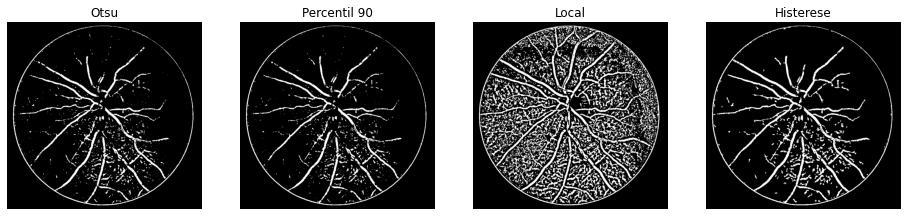

In [6]:
def threshold_image(enh, fov, method='hysteresis', **kw):
    vals=enh[fov]
    if method=='otsu':
        return (enh>threshold_otsu(vals))&fov
    if method=='percentile':
        return (enh>np.percentile(vals,kw.get('p',90)))&fov
    if method=='local':
        loc=threshold_local(enh,kw.get('block',51),offset=-kw.get('off',2))
        return (enh>loc)&(enh>kw.get('floor',10))&fov
    if method=='hysteresis':
        lo=np.percentile(vals,kw.get('p_lo',85)); hi=np.percentile(vals,kw.get('p_hi',93))
        return apply_hysteresis_threshold(enh,lo,hi)&fov
    raise ValueError(method)

methods={'Otsu':('otsu',{}),'Percentil 90':('percentile',{'p':90}),
         'Local':('local',{}),'Histerese':('hysteresis',{'p_lo':85,'p_hi':93})}
fig,ax=plt.subplots(1,4,figsize=(16,4))
for a,(name,(m,kw)) in zip(ax,methods.items()):
    a.imshow(threshold_image(enh,fov,m,**kw),cmap='gray'); a.set_title(name); a.axis('off')
plt.show()


## 5. Etapa 3 — limpeza morfológica dentro do FOV

A limpeza reduz defeitos da máscara bruta. Primeiro afastamos pixels do limite do FOV (`border`) para evitar artefatos de borda. Depois fechamos pequenas lacunas (`close_r`), removemos componentes com área menor que `min_size` e preenchemos buracos menores que `hole`. Ao final, recortamos novamente pelo FOV.

O parâmetro `min_size` é delicado: um valor alto elimina fragmentos de vasos verdadeiros, especialmente vasos finos.


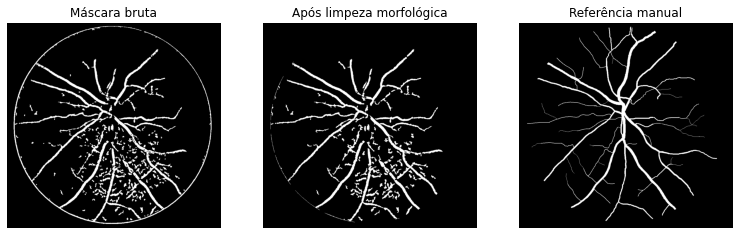

In [7]:
def disk_se(r): return cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(2*r+1,2*r+1))
def erode_fov(mask,r): return cv2.erode(mask.astype(np.uint8),disk_se(r)).astype(bool)
def remove_small(mask,min_size,connectivity=8):
    n,labels,stats,_=cv2.connectedComponentsWithStats(mask.astype(np.uint8),connectivity=connectivity)
    keep=np.zeros(n,dtype=bool); keep[1:]=stats[1:,cv2.CC_STAT_AREA]>=min_size
    return keep[labels]
def fill_small_holes(mask,max_hole):
    return ~remove_small(~mask,max_hole+1,connectivity=4)
def clean_mask(bw,fov,min_size=80,close_r=1,hole=30,border=4):
    bw=bw&erode_fov(fov,border)
    if close_r>0:
        bw=cv2.morphologyEx(bw.astype(np.uint8),cv2.MORPH_CLOSE,disk_se(close_r)).astype(bool)
    bw=remove_small(bw,min_size)
    bw=fill_small_holes(bw,hole)
    return bw&fov

bw_raw=threshold_image(enh,fov,'hysteresis',p_lo=85,p_hi=93)
bw_clean=clean_mask(bw_raw,fov)
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(bw_raw,cmap='gray'); ax[0].set_title('Máscara bruta')
ax[1].imshow(bw_clean,cmap='gray'); ax[1].set_title('Após limpeza morfológica')
ax[2].imshow(gt,cmap='gray'); ax[2].set_title('Referência manual')
for a in ax:a.axis('off')
plt.show()


## 6. Etapa 4 — esqueletização, comprimento e ramificações

A esqueletização reduz os vasos a linhas de 1 pixel. Ramos curtos podem surgir devido a irregularidades; a poda remove pontas em iterações, mas também pode remover extremidades verdadeiras. Aqui contamos pixels do esqueleto com pelo menos três vizinhos em 8-conectividade e agrupamos pixels adjacentes de um cruzamento.

O comprimento padrão abaixo é o número de pixels do esqueleto.

Comprimento aproximado (px): 7056.0
Componentes de ramificação: 182


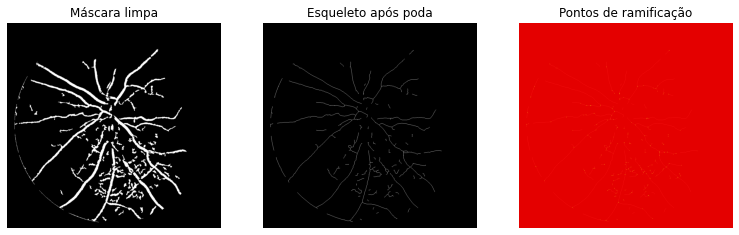

In [8]:
K8=np.ones((3,3),np.uint8); K8[1,1]=0
def neighbor_count(sk): return convolve(sk.astype(np.uint8),K8,mode='constant')*sk
def prune_skeleton(sk,n):
    sk=sk.copy()
    for _ in range(n):
        sk[(neighbor_count(sk)==1)&sk]=False
    return sk
def branch_points(sk):
    bp=(neighbor_count(sk)>=3)&sk
    n,_=cv2.connectedComponents(bp.astype(np.uint8),connectivity=8)
    return n-1,bp
def vessel_length(sk):
    return float(sk.sum())
def skeleton_stats(mask,prune_n=10):
    sk=skeletonize(mask)
    sk=remove_small(prune_skeleton(sk,prune_n),10)
    n_bp,bp=branch_points(sk)
    return {'skel':sk,'bp':bp,'length':vessel_length(sk),'branches':int(n_bp)}

stats=skeleton_stats(bw_clean,prune_n=10)
print('Comprimento aproximado (px):',stats['length'])
print('Componentes de ramificação:',stats['branches'])
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(bw_clean,cmap='gray'); ax[0].set_title('Máscara limpa')
ax[1].imshow(stats['skel'],cmap='gray'); ax[1].set_title('Esqueleto após poda')
ax[2].imshow(stats['skel'],cmap='gray'); ax[2].imshow(stats['bp'],cmap='autumn',alpha=.9); ax[2].set_title('Pontos de ramificação')
for a in ax:a.axis('off')
plt.show()


## 7. Pipeline integrado e métricas

As métricas binárias são calculadas somente no FOV. `Dice` e `IoU` medem sobreposição; sensibilidade é a fração de vasos de referência recuperados; especificidade é a fração de fundo corretamente rejeitada. Comprimento e ramificações são comparados com a referência manual, esqueletizada e podada pelo mesmo procedimento. Esses indicadores topológicos são aproximados e dependem da definição de poda e conectividade.


In [9]:
DEFAULT={'enhancer':'clahe_tophat','clip':2.0,'tile':8,'se':15,'smooth':1.0,
         'method':'hysteresis','p_hi':93,'p_lo':85,'min_size':80,'close_r':1,'hole':30,'border':4,'prune_n':10}
def run_pipeline(rgb,fov,**kwargs):
    p={**DEFAULT,**kwargs}
    response=enhance(rgb,fov,p['enhancer'],p['clip'],p['tile'],p['se'],p['smooth'])
    tkw={k:p[k] for k in ('p','p_hi','p_lo','block','off','floor') if k in p}
    raw=threshold_image(response,fov,p['method'],**tkw)
    bw=clean_mask(raw,fov,p['min_size'],p['close_r'],p['hole'],p['border'])
    return {'enh':response,'bw0':raw,'bw':bw,**skeleton_stats(bw,p['prune_n'])}
def segmentation_metrics(pred,gt,fov):
    p,g=pred[fov],gt[fov]
    tp=np.sum(p&g); fp=np.sum(p&~g); fn=np.sum(~p&g); tn=np.sum(~p&~g)
    return {'dice':2*tp/(2*tp+fp+fn+1e-9),'iou':tp/(tp+fp+fn+1e-9),
            'sensitivity':tp/(tp+fn+1e-9),'specificity':tn/(tn+fp+1e-9),
            'accuracy':(tp+tn)/(tp+tn+fp+fn+1e-9)}
def relative_error(a,b): return abs(a-b)/max(float(b),1e-9)
def evaluate_ids(ids,**kwargs):
    rows=[]
    for idx in ids:
        image,mask,ref=load_image(idx)
        result=run_pipeline(image,mask,**kwargs)
        reference=skeleton_stats(ref&mask,{**DEFAULT,**kwargs}['prune_n'])
        row=segmentation_metrics(result['bw'],ref,mask)
        row.update(id=idx,length=result['length'],reference_length=reference['length'],
                   length_error=relative_error(result['length'],reference['length']),
                   branches=result['branches'],reference_branches=reference['branches'],
                   branch_error=relative_error(result['branches'],reference['branches']))
        rows.append(row)
    return pd.DataFrame(rows)

one=run_pipeline(rgb,fov)
print(segmentation_metrics(one['bw'],gt,fov))


{'dice': np.float64(0.5821891590527021), 'iou': np.float64(0.41062541083669346), 'sensitivity': np.float64(0.6843248107357209), 'specificity': np.float64(0.9450364563169426), 'accuracy': np.float64(0.9251757349423789)}


## 8. Comparação de alternativas no desenvolvimento

Comparamos primeiro os quatro realces usando o mesmo limiar de histerese. Depois comparamos quatro limiarizadores usando o realce principal. Wilcoxon pareado é aplicado aos Dice por imagem entre a melhor média e cada alternativa. Com dez imagens, os valores de p devem ser interpretados com cautela.


In [10]:
images = sorted([arquivo.stem for arquivo in (DATA_ROOT/'images').iterdir() if arquivo.is_file()])
DEV_IDS=images[:14]
FINAL_IDS=images[14:]
def compare_variants(ids,variants,base_kwargs):
    results={name:evaluate_ids(ids,**{**base_kwargs,**params}) for name,params in variants.items()}
    summary=[]
    for name,df in results.items():
        row={'variant':name}
        for metric in ['dice','iou','sensitivity','specificity','length_error','branch_error']:
            row[metric+'_mean']=df[metric].mean(); row[metric+'_sd']=df[metric].std()
        summary.append(row)
    summary=pd.DataFrame(summary).sort_values('dice_mean',ascending=False)
    best=summary.iloc[0]['variant']; tests=[]
    for name,df in results.items():
        if name==best: continue
        try: p=float(wilcoxon(results[best]['dice'],df['dice']).pvalue)
        except ValueError: p=np.nan
        tests.append({'best':best,'other':name,'p_wilcoxon':p})
    return summary,pd.DataFrame(tests),results

enhancer_variants={'Verde + CLAHE + top-hat':{'enhancer':'clahe_tophat'},
                   'Verde + top-hat':{'enhancer':'tophat'},'Verde + CLAHE':{'enhancer':'clahe'},'Frangi':{'enhancer':'frangi'}}
threshold_variants={'Otsu':{'method':'otsu'},'Percentil 90':{'method':'percentile','p':90},
                    'Local adaptativo':{'method':'local'},'Histerese':{'method':'hysteresis'}}
enh_summary,enh_tests,enh_details=compare_variants(DEV_IDS,enhancer_variants,{'method':'hysteresis'})
thr_summary,thr_tests,thr_details=compare_variants(DEV_IDS,threshold_variants,{'enhancer':'clahe_tophat'})
display(enh_summary.round(3)); display(enh_tests.round(4))
display(thr_summary.round(3)); display(thr_tests.round(4))


,variant,dice_mean,dice_sd,iou_mean,iou_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,length_error_mean,length_error_sd,branch_error_mean,branch_error_sd
0,Verde + CLAHE + top-hat,0.657,0.041,0.491,0.045,0.628,0.041,0.965,0.006,0.295,0.039,1.902,0.562
1,Verde + top-hat,0.650,0.040,0.482,0.044,0.615,0.039,0.965,0.007,0.311,0.040,1.837,0.532
3,Frangi,0.331,0.054,0.199,0.037,0.226,0.045,0.983,0.007,0.380,0.133,2.863,1.362
2,Verde + CLAHE,0.293,0.081,0.174,0.057,0.306,0.080,0.901,0.013,0.462,0.085,1.843,0.847


,best,other,p_wilcoxon
0,Verde + CLAHE + top-hat,Verde + top-hat,0.0017
1,Verde + CLAHE + top-hat,Verde + CLAHE,0.0001
2,Verde + CLAHE + top-hat,Frangi,0.0001


,variant,dice_mean,dice_sd,iou_mean,iou_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,length_error_mean,length_error_sd,branch_error_mean,branch_error_sd
3,Histerese,0.657,0.041,0.491,0.045,0.628,0.041,0.965,0.006,0.295,0.039,1.902,0.562
0,Otsu,0.645,0.037,0.477,0.041,0.587,0.040,0.971,0.010,0.350,0.057,1.629,0.622
1,Percentil 90,0.600,0.044,0.430,0.044,0.489,0.045,0.983,0.003,0.504,0.044,0.749,0.312
2,Local adaptativo,0.392,0.017,0.244,0.013,0.817,0.019,0.706,0.012,2.071,0.292,28.935,5.371


,best,other,p_wilcoxon
0,Histerese,Otsu,0.0017
1,Histerese,Percentil 90,0.0001
2,Histerese,Local adaptativo,0.0001


## 9. Análise de sensibilidade dos parâmetros

Fazemos varredura univariada: variamos um parâmetro de cada vez, mantendo os demais nos valores padrão. A seleção de cada valor maximiza o Dice médio no conjunto de desenvolvimento. Esse método é transparente, mas não procura interações entre parâmetros nem garante ótimo global. **Não** use o conjunto reservado 31–40 para tomar decisões de ajuste.


clip → 1 | Dice 0.6588
tile → 4 | Dice 0.6596
se → 21 | Dice 0.6915
smooth → 2.0 | Dice 0.6812
p_hi → 88 | Dice 0.6593
min_size → 150 | Dice 0.6601
prune_n → 0 | Dice 0.6575


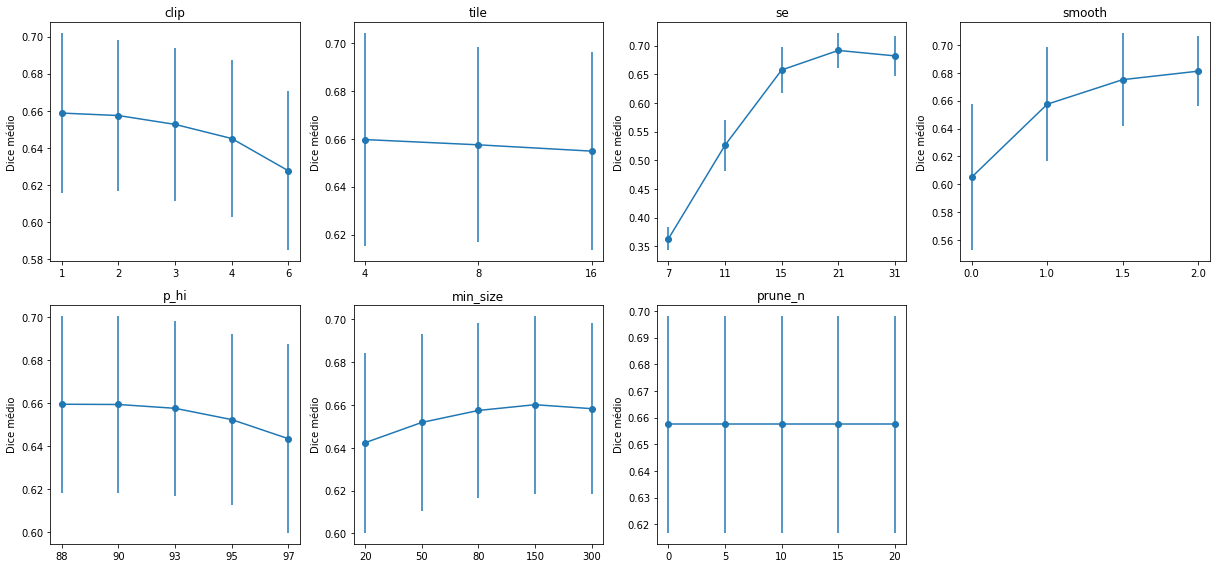

In [11]:
PARAM_GRID={'clip':[1,2,3,4,6],'tile':[4,8,16],'se':[7,11,15,21,31],
            'smooth':[0,1,1.5,2],'p_hi':[88,90,93,95,97],
            'min_size':[20,50,80,150,300],'prune_n':[0,5,10,15,20]}
def sweep_parameter(ids,param,values):
    rows=[]
    for value in values:
        df=evaluate_ids(ids,**{param:value})
        rows.append({'param':param,'value':value,'dice':df.dice.mean(),'dice_sd':df.dice.std(),
                     'iou':df.iou.mean(),'sensitivity':df.sensitivity.mean(),'specificity':df.specificity.mean(),
                     'length_error':df.length_error.mean(),'branch_error':df.branch_error.mean()})
    return pd.DataFrame(rows)

sensitivity_tables={}
selected={}
for param,values in PARAM_GRID.items():
    table=sweep_parameter(DEV_IDS,param,values)
    sensitivity_tables[param]=table
    selected[param]=table.loc[table.dice.idxmax(),'value'].item()
    print(param,'→',selected[param],'| Dice',round(table.dice.max(),4))

fig,axes=plt.subplots(2,4,figsize=(17,8)); axes=axes.ravel()
for ax,(param,table) in zip(axes,sensitivity_tables.items()):
    x=np.arange(len(table)); ax.errorbar(x,table.dice,yerr=table.dice_sd,marker='o')
    ax.set_xticks(x); ax.set_xticklabels(table.value); ax.set_title(param); ax.set_ylabel('Dice médio')
for ax in axes[len(sensitivity_tables):]: ax.axis('off')
plt.tight_layout(); plt.show()


## 10. Estudo de ruído e PSNR

Para compreender robustez, adicionamos ruído Gaussiano de desvio-padrão σ=0, 10, 20 e 30 níveis de intensidade a cinco imagens do grupo de desenvolvimento. Comparamos nenhum filtro, Gaussiano, mediana e bilateral. O PSNR quantifica diferença entre canal verde processado e original dentro do FOV. Quando σ=0 e não há filtro, as imagens coincidem; o notebook usa 99 dB como valor sentinela para igualdade exata.

Este experimento simulado mede sensibilidade a ruído sintético e não substitui imagens com ruído real de aquisição.


In [12]:
denoisers={'Nenhum':lambda g:g,'Gaussiano σ=1':lambda g:cv2.GaussianBlur(g,(0,0),1),
           'Mediana 3×3':lambda g:cv2.medianBlur(g,3),
           'Bilateral':lambda g:cv2.bilateralFilter(g,5,25,3)}
def psnr(a,b,mask):
    mse=np.mean((a[mask].astype(float)-b[mask].astype(float))**2)
    return 99.0 if mse==0 else 10*np.log10(255.0**2/mse)
noise_rows=[]
for idx in DEV_IDS[:5]:
    image,mask,ref=load_image(idx)
    green=image[...,1]
    for sigma in [0,10,20,30]:
        rng=np.random.default_rng(SEED+sigma)
        noisy=green if sigma==0 else np.clip(green.astype(float)+rng.normal(0,sigma,green.shape),0,255).astype(np.uint8)
        for name,denoise in denoisers.items():
            filtered=denoise(noisy)
            image2=image.copy(); image2[...,1]=filtered
            pred=run_pipeline(image2,mask)['bw']
            noise_rows.append({'id':idx,'sigma':sigma,'filter':name,'psnr':psnr(filtered,green,mask),
                               'dice':segmentation_metrics(pred,ref,mask)['dice']})
noise_df=pd.DataFrame(noise_rows)
noise_summary=noise_df.groupby(['sigma','filter'])[['psnr','dice']].mean().reset_index()
display(noise_summary.round(3))


,sigma,filter,psnr,dice
0,0,Bilateral,43.419,0.660
1,0,Gaussiano σ=1,43.893,0.659
2,0,Mediana 3×3,45.790,0.656
3,0,Nenhum,99.000,0.642
4,10,Bilateral,36.614,0.593
5,10,Gaussiano σ=1,37.713,0.595
6,10,Mediana 3×3,35.237,0.565
7,10,Nenhum,28.152,0.548
8,20,Bilateral,27.757,0.403
9,20,Gaussiano σ=1,32.789,0.440


## 11. Congelar parâmetros e avaliação final reservada

Combinamos os melhores valores marginais obtidos no grupo de desenvolvimento com os parâmetros padrão que não foram variados. Em seguida executamos uma única avaliação em 31–40. Esta célula deve vir **depois** de todas as decisões de método e parâmetro.

Se quiser aderir estritamente ao relatório original, que congelou o padrão sem otimização, substitua `FINAL_PARAMS` pelos valores padrão de `DEFAULT`. Aqui usamos a varredura de desenvolvimento para que o notebook mostre como escolher e congelar parâmetros.


In [13]:
FINAL_PARAMS={**DEFAULT,**selected}
print('Parâmetros congelados:',json.dumps(FINAL_PARAMS,indent=2))
final_df=evaluate_ids(FINAL_IDS,**FINAL_PARAMS)
final_summary=final_df[['dice','iou','sensitivity','specificity','length_error','branch_error']].agg(['mean','std']).T
print('Resumo da avaliação reservada:')
display(final_summary.round(4))
display(final_df.round(4))


Parâmetros congelados: {
  "enhancer": "clahe_tophat",
  "clip": 1,
  "tile": 4,
  "se": 21,
  "smooth": 2.0,
  "method": "hysteresis",
  "p_hi": 88,
  "p_lo": 85,
  "min_size": 150,
  "close_r": 1,
  "hole": 30,
  "border": 4,
  "prune_n": 0
}
Resumo da avaliação reservada:


,mean,std
dice,0.6358,0.0384
iou,0.4672,0.0411
sensitivity,0.7457,0.0260
specificity,0.9424,0.0066
length_error,0.1569,0.0874
branch_error,1.2209,0.7201


,dice,iou,sensitivity,specificity,accuracy,id,length,reference_length,length_error,branches,reference_branches,branch_error
0,0.6516,0.4833,0.7284,0.9445,0.9232,Image_08L,7969.0,10157.0,0.2154,115,81,0.4198
1,0.6791,0.5141,0.7540,0.9500,0.9310,Image_08R,7658.0,9314.0,0.1778,115,54,1.1296
2,0.5674,0.3960,0.7467,0.9307,0.9174,Image_09L,9159.0,8141.0,0.1250,149,54,1.7593
3,0.5717,0.4003,0.7403,0.9331,0.9191,Image_09R,9173.0,8803.0,0.0420,154,58,1.6552
4,0.6060,0.4347,0.7037,0.9388,0.9176,Image_10L,8711.0,11094.0,0.2148,180,85,1.1176
5,0.6240,0.4535,0.7159,0.9434,0.9231,Image_10R,7767.0,11675.0,0.3347,137,95,0.4421
6,0.6200,0.4493,0.7803,0.9393,0.9272,Image_11L,8712.0,9184.0,0.0514,104,61,0.7049
7,0.6164,0.4455,0.7943,0.9353,0.9245,Image_11R,9441.0,8463.0,0.1156,144,54,1.6667
8,0.6421,0.4729,0.7163,0.9404,0.9172,Image_12L,8630.0,11210.0,0.2302,129,79,0.6329
9,0.6920,0.5291,0.7461,0.9516,0.9299,Image_12R,9246.0,12071.0,0.2340,143,88,0.6250


## 12. Análise de falhas

Selecionamos automaticamente o pior e o melhor caso pelo Dice do conjunto reservado apenas para **descrever** o comportamento após a avaliação. O mapa de erro usa verde para verdadeiro positivo, vermelho para falso positivo e azul para falso negativo; pixels fora do FOV aparecem em cinza. A sensibilidade por largura estima a largura local pela transformada de distância da referência e calcula a fração do esqueleto de referência recuperada com tolerância de um pixel.


Pior Dice: Image_09L | melhor Dice: Image_12R


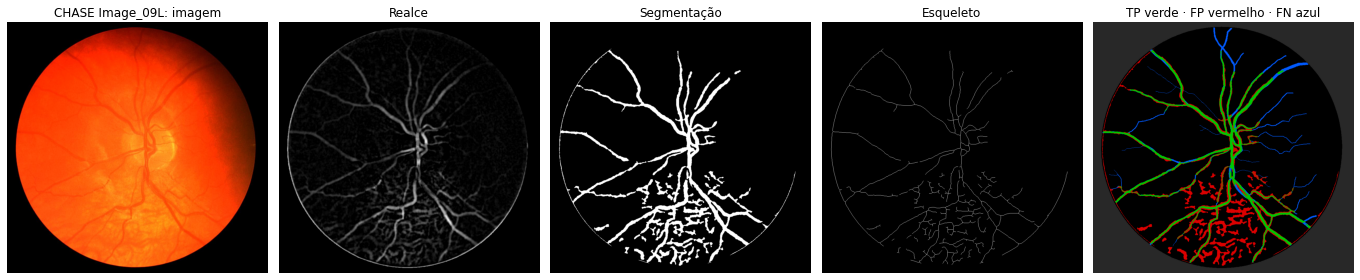

Métricas: {'dice': np.float64(0.5673848852964859), 'iou': np.float64(0.3960483729880992), 'sensitivity': np.float64(0.7467169686849168), 'specificity': np.float64(0.9307267489685368), 'accuracy': np.float64(0.9173748431191562)}
Recall por largura:


,width_px,reference_skeleton_pixels,recall
0,0–3,2316,0.268998
1,3–5,1265,0.652174
2,5–7,1575,0.855238
3,7–30,2986,0.899196


Maiores componentes FP (coordenadas em pixels):


,x_px,y_px,area_px
0,532,753,4872
1,493,897,1937
2,517,842,1845
3,428,891,1021
4,116,242,923


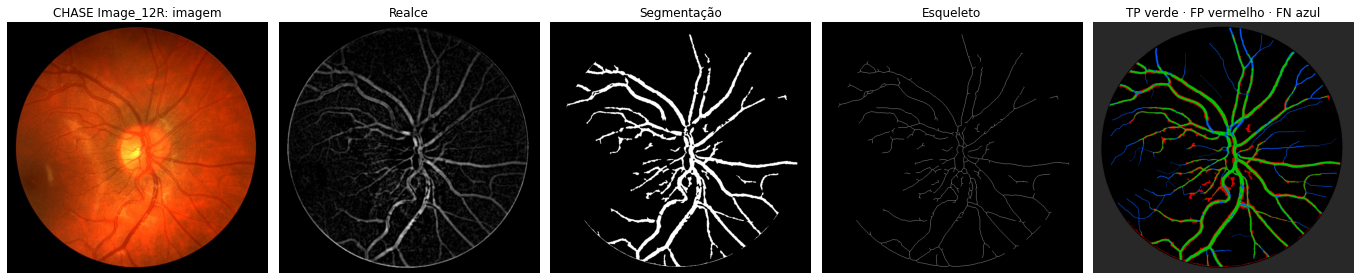

Métricas: {'dice': np.float64(0.6920222634508304), 'iou': np.float64(0.5290780141843918), 'sensitivity': np.float64(0.7460952462016321), 'specificity': np.float64(0.951616789713588), 'accuracy': np.float64(0.929932120431973)}
Recall por largura:


,width_px,reference_skeleton_pixels,recall
0,0–3,3799,0.206897
1,3–5,2454,0.667482
2,5–7,1563,0.852207
3,7–30,4255,0.929025


Maiores componentes FP (coordenadas em pixels):


,x_px,y_px,area_px
0,534,609,368
1,594,407,324
2,593,918,310
3,595,581,308
4,501,646,268


In [14]:
def error_map(pred,gt,fov):
    out=np.zeros(pred.shape+(3,),np.uint8)
    out[pred&gt]=(0,200,0)       # verdadeiro positivo (RGB verde)
    out[pred&~gt]=(220,0,0)     # falso positivo
    out[~pred&gt]=(0,90,255)     # falso negativo
    out[~fov]=(40,40,40)
    return out

def recall_by_width(pred,gt,fov,edges=(0,3,5,7,30)):
    distance=cv2.distanceTransform(gt.astype(np.uint8),cv2.DIST_L2,5)
    sk=skeletonize(gt)&fov
    widths=2*distance[sk]
    hit=cv2.dilate(pred.astype(np.uint8),np.ones((3,3),np.uint8)).astype(bool)[sk]
    rows=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        group=(widths>=lo)&(widths<hi)
        rows.append({'width_px':f'{lo}–{hi}','reference_skeleton_pixels':int(group.sum()),
                     'recall':float(hit[group].mean()) if group.any() else np.nan})
    return pd.DataFrame(rows)

def worst_fp_components(pred,gt,fov,k=5):
    tolerance=disk_se(2)
    fp=pred&~cv2.dilate(gt.astype(np.uint8),tolerance).astype(bool)&fov
    fp=remove_small(fp,15)
    n,labels,stats,centroids=cv2.connectedComponentsWithStats(fp.astype(np.uint8),connectivity=8)
    order=np.argsort(-stats[1:,cv2.CC_STAT_AREA])[:k]+1
    return pd.DataFrame([{'x_px':int(centroids[i,0]),'y_px':int(centroids[i,1]),
                          'area_px':int(stats[i,cv2.CC_STAT_AREA])} for i in order])

worst_id=final_df.loc[final_df.dice.idxmin(),'id']
best_id=final_df.loc[final_df.dice.idxmax(),'id']
print('Pior Dice:',worst_id,'| melhor Dice:',best_id)
def show_case(idx):
    image,mask,ref=load_image(idx)
    result=run_pipeline(image,mask,**FINAL_PARAMS)
    fig,ax=plt.subplots(1,5,figsize=(19,4))
    ax[0].imshow(image); ax[0].set_title(f'CHASE {idx}: imagem')
    ax[1].imshow(result['enh'],cmap='gray'); ax[1].set_title('Realce')
    ax[2].imshow(result['bw'],cmap='gray'); ax[2].set_title('Segmentação')
    ax[3].imshow(result['skel'],cmap='gray'); ax[3].set_title('Esqueleto')
    ax[4].imshow(error_map(result['bw'],ref,mask)); ax[4].set_title('TP verde · FP vermelho · FN azul')
    for a in ax:a.axis('off')
    plt.tight_layout(); plt.show()
    print('Métricas:',segmentation_metrics(result['bw'],ref,mask))
    print('Recall por largura:'); display(recall_by_width(result['bw'],ref,mask))
    print('Maiores componentes FP (coordenadas em pixels):'); display(worst_fp_components(result['bw'],ref,mask))
    return result
worst_result=show_case(worst_id)
best_result=show_case(best_id)


### Interpretação guiada

Ao inspecionar os mapas, procure: vasos finos perdidos (azul); respostas falsas em lesões, reflexos ou disco óptico (vermelho); anéis junto à borda do FOV; vasos largos com lacunas centrais; fusões de vasos próximos; e ramos espúrios no esqueleto. Para cada falha registrada, escreva a evidência observada, a causa provável, a ligação com o operador usado e uma possível melhoria. Não declare causa anatômica apenas com base em uma coordenada de falso positivo.


## 13. Salvar tabelas, parâmetros e figuras

Salvamos CSVs e parâmetros no diretório `resultados/`. O notebook também salva uma imagem de exemplo do pipeline. Para levar os resultados ao computador, é possível compactar a pasta e iniciar o download pelo Colab.


In [15]:
OUT=DATA_ROOT/'resultados'; FIG=OUT/'figuras'; TAB=OUT/'tabelas'
FIG.mkdir(parents=True,exist_ok=True); TAB.mkdir(parents=True,exist_ok=True)
enh_summary.to_csv(TAB/'comparacao_realce.csv',index=False)
enh_tests.to_csv(TAB/'comparacao_realce_wilcoxon.csv',index=False)
thr_summary.to_csv(TAB/'comparacao_limiar.csv',index=False)
thr_tests.to_csv(TAB/'comparacao_limiar_wilcoxon.csv',index=False)
noise_summary.to_csv(TAB/'ruido_psnr.csv',index=False)
noise_df.to_csv(TAB/'ruido_por_imagem.csv',index=False)
final_df.to_csv(TAB/'avaliacao_final_por_imagem.csv',index=False)
final_summary.to_csv(TAB/'avaliacao_final_resumo.csv')
all_sensitivity=pd.concat(sensitivity_tables.values(),ignore_index=True)
all_sensitivity.to_csv(TAB/'sensibilidade.csv',index=False)
for name,table in sensitivity_tables.items(): table.to_csv(TAB/f'sensibilidade_{name}.csv',index=False)
with open(OUT/'parametros_finais.json','w') as f: json.dump(FINAL_PARAMS,f,indent=2)
for idx in (worst_id,best_id):
    image,mask,ref=load_image(idx); result=run_pipeline(image,mask,**FINAL_PARAMS)
    fig,ax=plt.subplots(1,5,figsize=(18,4))
    ax[0].imshow(image); ax[0].set_title('Imagem')
    ax[1].imshow(result['enh'],cmap='gray'); ax[1].set_title('Realce')
    ax[2].imshow(result['bw'],cmap='gray'); ax[2].set_title('Segmentação')
    ax[3].imshow(result['skel'],cmap='gray'); ax[3].set_title('Esqueleto')
    ax[4].imshow(error_map(result['bw'],ref,mask)); ax[4].set_title('Mapa de erros')
    for a in ax:a.axis('off')
    plt.tight_layout(); fig.savefig(FIG/f'pipeline_{idx}.png',dpi=140,bbox_inches='tight'); plt.close(fig)
print('Arquivos salvos em',OUT)


Arquivos salvos em CHASE\resultados


## 15. Conclusões e limitações

Ao finalizar a execução, descreva os resultados produzidos pelas células, sem substituir os valores reais por valores de exemplo. Discuta qual realce e limiarização tiveram melhor desempenho; se as diferenças pareadas foram estatisticamente claras; quais parâmetros foram sensíveis; como Dice, sensibilidade e especificidade se comportaram no grupo reservado; e quais falhas aparecem nos mapas e por largura de vaso.

Limitações importantes: somente dez imagens para desenvolvimento e dez para avaliação reservada; uma anotação manual por imagem de treino; parâmetro em pixels dependente da resolução; contagem aproximada de comprimento; ramo definido por vizinhança de oito pixels; e ausência de validação externa neste notebook. O método é para processamento e avaliação acadêmica, não diagnóstico clínico.

## Referências

[1] FRAZ, Muhammad Moazam et al. An ensemble classification-based approach applied to retinal blood vessel segmentation. IEEE transactions on biomedical engineering, v. 59, n. 9, p. 2538-2548, 2012.\n
[2] Staal, J. et al. (2004). “Ridge-based vessel segmentation in color images of the retina.” *IEEE Transactions on Medical Imaging*, 23(4), 501–509. DOI: <https://doi.org/10.1109/TMI.2004.825627>.
